# 1. Imports
This section loads standard libraries, platform packages, Lightning, PyTorch, and the project source code modules.

In [20]:
# This notebook lives in `extra/`. Move the CWD up to the project root
# so that `src.*` imports resolve and dataset paths are correct.
import os, sys
from pathlib import Path

if Path.cwd().name == "extra":
    os.chdir(Path.cwd().parent)
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"[INFO] Project root: {PROJECT_ROOT}")


[INFO] Project root: c:\Users\andre\Desktop\CV-project-25-26


In [21]:
import platform
import random
import numpy as np
import torch
import lightning as L

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
L.seed_everything(SEED, workers=True)

# Optional: mount Drive on Colab T4
if torch.cuda.is_available() and torch.cuda.get_device_name(0) == "Tesla T4":
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_ROOT = "/content/drive/MyDrive/CV-project-25-26"
        if DRIVE_ROOT not in sys.path:
            sys.path.insert(0, DRIVE_ROOT)
        os.chdir(DRIVE_ROOT)
        print(f"[INFO] Colab T4 — CWD: {os.getcwd()}")
    except Exception as e:
        print(f"[INFO] Not on Colab ({e})")

print("[OK] Seeds + environment configured")


Seed set to 42


[OK] Seeds + environment configured


In [22]:
# Project imports — current API
from src.config import (
    DEVICE,
    ARCH_TYPE,
    RGB_img_res,
    IMG_SIZE,
    NYU_SIZE,
    KITTI_SIZE,
    SSL_BATCH_SIZE,
    FT_BATCH_SIZE,
    DATASET_NYU_PATH,
    DATASET_KITTI_PATH,
    DATASET_KITTI_PATH_GT,
    MODEL_SAVE_PATH,
    SSL_CKPT_PATH,
)
from src.network    import METERModel
from src.dataset    import NYUDataset, KITTIDataset, build_dataloader, get_ssl_transform
from src.train      import LeJEPAMeter, METERFinetune, balanced_loss_function
from src.evaluation import geometric_probing_pca, extract_features

print("[OK] All project modules imported")


[OK] All project modules imported


# 2. Globals
This section verifies the global environment (OS, CUDA, PyTorch, GPUs) and runs checks on dataset directory paths.

## Test 1 — Environment

In [23]:
print("=== ENVIRONMENT ===")
print(f"OS              : {platform.system()} {platform.release()}")
print(f"Python          : {platform.python_version()}")
print(f"PyTorch         : {torch.__version__}")
print(f"Lightning       : {L.__version__}")
print(f"Device          : {DEVICE}")
print(f"CUDA available  : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU             : {torch.cuda.get_device_name(0)}")
    print(f"CUDA version    : {torch.version.cuda}")
if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    print("MPS available   : True")

print()
print("=== PROJECT CONFIG ===")
print(f"ARCH_TYPE       : {ARCH_TYPE}")
print(f"RGB_img_res     : {RGB_img_res}")
print(f"IMG_SIZE        : {IMG_SIZE}")
print(f"NYU_SIZE        : {NYU_SIZE}  (paper: 192x256)")
print(f"KITTI_SIZE      : {KITTI_SIZE}  (paper: 192x636)")
print(f"SSL_BATCH_SIZE  : {SSL_BATCH_SIZE}")
print(f"FT_BATCH_SIZE   : {FT_BATCH_SIZE}")
print(f"MODEL_SAVE_PATH : {MODEL_SAVE_PATH}")
print("\n[OK] Environment initialized")


=== ENVIRONMENT ===
OS              : Windows 11
Python          : 3.12.7
PyTorch         : 2.12.0.dev20260408+cu128
Lightning       : 2.6.1
Device          : cuda
CUDA available  : True
GPU             : NVIDIA GeForce RTX 5070 Laptop GPU
CUDA version    : 12.8

=== PROJECT CONFIG ===
ARCH_TYPE       : xxs
RGB_img_res     : (3, 256, 256)
IMG_SIZE        : (256, 256)
NYU_SIZE        : (192, 256)  (paper: 192x256)
KITTI_SIZE      : (192, 636)  (paper: 192x636)
SSL_BATCH_SIZE  : 64
FT_BATCH_SIZE   : 128
MODEL_SAVE_PATH : C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints

[OK] Environment initialized


## Test 2 — Dataset paths on disk

In [24]:
print("=== DATA CHECK ===\n")

print("[NYU Depth V2]")
nyu_root = Path(DATASET_NYU_PATH)
nyu_mat  = nyu_root / "nyu_depth_v2_labeled.mat"
print(f"  Root       : {nyu_root}")
print(f"  Exists     : {nyu_root.exists()}")
print(f"  .mat file  : {nyu_mat.name}  (exists={nyu_mat.exists()})")
if nyu_root.exists():
    n_jpg = sum(1 for _ in nyu_root.rglob('*.jpg'))
    n_h5  = sum(1 for _ in nyu_root.rglob('*.h5'))
    print(f"  .jpg files : {n_jpg}")
    print(f"  .h5  files : {n_h5}")

print("\n[KITTI Depth]")
kitti_root    = Path(DATASET_KITTI_PATH) if DATASET_KITTI_PATH else None
kitti_gt_root = Path(DATASET_KITTI_PATH_GT) if DATASET_KITTI_PATH_GT else None
if kitti_root:
    print(f"  RGB root   : {kitti_root}  (exists={kitti_root.exists()})")
if kitti_gt_root:
    print(f"  GT  root   : {kitti_gt_root}  (exists={kitti_gt_root.exists()})")

NYU_AVAILABLE   = nyu_root.exists() and (
    nyu_mat.exists()
    or any(nyu_root.rglob('*.jpg'))
    or any(nyu_root.rglob('*.h5'))
)
KITTI_AVAILABLE = (kitti_root is not None and kitti_root.exists()
                   and kitti_gt_root is not None and kitti_gt_root.exists())
print(f"\nNYU_AVAILABLE   : {NYU_AVAILABLE}")
print(f"KITTI_AVAILABLE : {KITTI_AVAILABLE}")


=== DATA CHECK ===

[NYU Depth V2]
  Root       : C:\Users\andre\Desktop\CV-project-25-26\data\raw\nyu
  Exists     : True
  .mat file  : nyu_depth_v2_labeled.mat  (exists=True)
  .jpg files : 48238
  .h5  files : 0

[KITTI Depth]
  RGB root   : C:\Users\andre\Desktop\CV-project-25-26\data\raw\kitti  (exists=True)
  GT  root   : C:\Users\andre\Desktop\CV-project-25-26\data\raw\kitti  (exists=True)

NYU_AVAILABLE   : True
KITTI_AVAILABLE : True


# 3. Utils
The notebook imports utility features from `src.utils` (such as reproducibility helpers, dataset checks, etc.) as part of the setup cells. No additional helper functions are defined locally.

# 4. Data
This section runs tests on DataLoaders building, batch shapes, data scales, multi-crop transforms, and dataset integrity.

## Test 3 — NYU fine-tuning dataloader & batch

In [25]:
print("=== NYU FINETUNE DATALOADER ===")

if not NYU_AVAILABLE:
    print("[SKIP] NYU not on disk")
    nyu_ft_loader, nyu_ft_batch = None, None
else:
    nyu_ds = NYUDataset(
        path  = DATASET_NYU_PATH,
        mode  = "finetune",
        split = "all",
        kaggle= False,
    )
    print(f"Samples: {len(nyu_ds)}")

    nyu_ft_loader = build_dataloader(
        nyu_ds,
        batch_size=min(4, FT_BATCH_SIZE),
        shuffle=True,
        drop_last=True,
    )

    nyu_ft_batch = next(iter(nyu_ft_loader))
    rgb, depth = nyu_ft_batch
    print(f"\n[Batch]")
    print(f"  RGB    : {tuple(rgb.shape)}  dtype={rgb.dtype}")
    print(f"  Depth  : {tuple(depth.shape)}  dtype={depth.dtype}")
    print(f"  Depth range (cm): [{depth.min().item():.1f}, {depth.max().item():.1f}]")
    print(f"  Depth mean (cm) : {depth.mean().item():.1f}")
    assert rgb.ndim == 4, "RGB must be [B, C, H, W]"
    assert depth.ndim == 4 and depth.shape[1] == 1, "Depth must be [B, 1, H, W]"
    assert rgb.shape[0] == depth.shape[0]
    print("\n[OK] NYU finetune loader works")


=== NYU FINETUNE DATALOADER ===

[INFO] NYUDataset — mode=finetune, split=all, kaggle=False
[INFO] NYUDataset — 48238 samples  (format=pairs)
Samples: 48238
[INFO] DataLoader — batch=4  workers=4  shuffle=True  pin_memory=True

[Batch]
  RGB    : (4, 3, 192, 256)  dtype=torch.float32
  Depth  : (4, 1, 192, 256)  dtype=torch.float32
  Depth range (cm): [0.0, 610.6]
  Depth mean (cm) : 349.0

[OK] NYU finetune loader works


## Test 4 — KITTI fine-tuning dataloader & batch (optional)

In [26]:
print("=== KITTI FINETUNE DATALOADER ===")

if not KITTI_AVAILABLE:
    print("[SKIP] KITTI not on disk")
    kitti_ft_loader, kitti_ft_batch = None, None
else:
    kitti_gt_subdir = Path(DATASET_KITTI_PATH_GT) / "depth"
    if not kitti_gt_subdir.exists():
        kitti_gt_subdir = Path(DATASET_KITTI_PATH_GT)

    kitti_rgb_root = Path(DATASET_KITTI_PATH) / "rgb"
    if not kitti_rgb_root.exists():
        kitti_rgb_root = Path(DATASET_KITTI_PATH)

    kitti_ds = KITTIDataset(
        path    = kitti_rgb_root,
        gt_root = kitti_gt_subdir,
        mode    = "finetune",
        split   = "val",
    )
    print(f"Samples: {len(kitti_ds)}")

    if len(kitti_ds) == 0:
        print("[WARN] KITTI dataset empty — skipping")
        kitti_ft_loader, kitti_ft_batch = None, None
    else:
        kitti_ft_loader = build_dataloader(kitti_ds, batch_size=2, shuffle=False, drop_last=False)
        kitti_ft_batch  = next(iter(kitti_ft_loader))
        rgb, depth = kitti_ft_batch
        print(f"\n[Batch]")
        print(f"  RGB    : {tuple(rgb.shape)}")
        print(f"  Depth  : {tuple(depth.shape)}")
        print(f"  Depth range (m): [{depth.min().item():.3f}, {depth.max().item():.3f}]")
        print(f"  Valid pixels (>0.001 m): {(depth > 0.001).float().mean().item():.3f}")
        print("\n[OK] KITTI finetune loader works")


=== KITTI FINETUNE DATALOADER ===

[INFO] KITTIDataset — mode=finetune, split=val
[INFO] KITTIDataset — 3347 samples
Samples: 3347
[INFO] DataLoader — batch=2  workers=4  shuffle=False  pin_memory=True

[Batch]
  RGB    : (2, 3, 192, 636)
  Depth  : (2, 1, 192, 636)
  Depth range (m): [0.000, 77.477]
  Valid pixels (>0.001 m): 0.111

[OK] KITTI finetune loader works


## Test 5 — SSL multi-crop transform sanity

Verifies that the SSL transform produces the expected resolutions: 256×256 (global) and 128×128 (local).

In [27]:
print("=== SSL MULTI-CROP TRANSFORM ===")
dummy_img = torch.rand(3, 480, 640)  # native NYU resolution

t_global = get_ssl_transform(global_view=True)
t_local  = get_ssl_transform(global_view=False)

g = t_global(dummy_img)
l = t_local(dummy_img)
print(f"Global crop : {tuple(g.shape)}   expected (3, 256, 256)")
print(f"Local crop  : {tuple(l.shape)}   expected (3, 128, 128)")
assert g.shape == (3, 256, 256), "Global crop shape mismatch"
assert l.shape == (3, 128, 128), "Local crop shape mismatch"
print("\n[OK] Multi-crop transform aligned with paper (2x256 + 6x128)")


=== SSL MULTI-CROP TRANSFORM ===
Global crop : (3, 256, 256)   expected (3, 256, 256)
Local crop  : (3, 128, 128)   expected (3, 128, 128)

[OK] Multi-crop transform aligned with paper (2x256 + 6x128)


## Test 9 — Transformed batch resolutions (paper alignment)

Paper Section IV-B: NYU 192×256, KITTI 192×636.

In [31]:
print("=== TRANSFORMED BATCHES — PAPER ALIGNMENT ===")

if NYU_AVAILABLE and nyu_ft_batch is not None:
    rgb, depth = nyu_ft_batch
    print("\n[NYU]")
    print(f"  RGB   : {tuple(rgb.shape)}   expected [B, 3, 192, 256]")
    print(f"  Depth : {tuple(depth.shape)}   expected [B, 1, 192, 256]")
    assert rgb.shape[-2:]   == (192, 256), f"NYU RGB shape mismatch: {rgb.shape}"
    assert depth.shape[-2:] == (192, 256), f"NYU Depth shape mismatch: {depth.shape}"
    print("  [OK] NYU resolutions align with paper")
else:
    print("[SKIP] NYU not available")

if KITTI_AVAILABLE and kitti_ft_batch is not None:
    rgb, depth = kitti_ft_batch
    print("\n[KITTI]")
    print(f"  RGB   : {tuple(rgb.shape)}   expected [B, 3, 192, 636]")
    print(f"  Depth : {tuple(depth.shape)}   expected [B, 1, 192, 636]")
    assert rgb.shape[-2:]   == (192, 636), f"KITTI RGB shape mismatch: {rgb.shape}"
    assert depth.shape[-2:] == (192, 636), f"KITTI Depth shape mismatch: {depth.shape}"
    print("  [OK] KITTI resolutions align with paper")
else:
    print("[SKIP] KITTI not available")


=== TRANSFORMED BATCHES — PAPER ALIGNMENT ===

[NYU]
  RGB   : (4, 3, 192, 256)   expected [B, 3, 192, 256]
  Depth : (4, 1, 192, 256)   expected [B, 1, 192, 256]
  [OK] NYU resolutions align with paper

[KITTI]
  RGB   : (2, 3, 192, 636)   expected [B, 3, 192, 636]
  Depth : (2, 1, 192, 636)   expected [B, 1, 192, 636]
  [OK] KITTI resolutions align with paper


## Test 15 — NYU depth scale investigation

Confirms GT is in **centimeters** (range ~50–1000 cm).

In [37]:
print("=== NYU DEPTH SCALE INVESTIGATION ===")
if not NYU_AVAILABLE:
    print("[SKIP] NYU not available")
else:
    ds_no_aug = NYUDataset(path=DATASET_NYU_PATH, mode="finetune", split="all", kaggle=False)
    ds_no_aug.aug = None  # disable random aug for inspection
    rgb, depth = ds_no_aug[0]

    print(f"RGB   shape : {tuple(rgb.shape)}")
    print(f"Depth shape : {tuple(depth.shape)}")

    print(f"\n[FULL — incl. zeros from holes / invalid]")
    print(f"  min   : {depth.min().item():.2f}")
    print(f"  max   : {depth.max().item():.2f}")
    print(f"  mean  : {depth.mean().item():.2f}")
    print(f"  zero %: {(depth == 0).float().mean().item()*100:.2f}")

    valid = depth[depth > 0]
    if valid.numel():
        print(f"\n[VALID (>0)]")
        print(f"  min   : {valid.min().item():.2f}")
        print(f"  max   : {valid.max().item():.2f}")
        print(f"  mean  : {valid.mean().item():.2f}")
        print(f"  P50   : {torch.quantile(valid, 0.5).item():.2f}")
        print(f"  P90   : {torch.quantile(valid, 0.9).item():.2f}")
        print(f"  P99   : {torch.quantile(valid, 0.99).item():.2f}")

    print("\n[INTERPRETATION]")
    if valid.numel() and 50 < valid.mean().item() < 600 and valid.max().item() < 1500:
        print("[OK] Depths look like NYU in cm (mean ~250, max < 1500)")
    else:
        print("[WARN] Depth scale doesn't match NYU cm convention — check dataset loader")


=== NYU DEPTH SCALE INVESTIGATION ===

[INFO] NYUDataset — mode=finetune, split=all, kaggle=False
[INFO] NYUDataset — 48238 samples  (format=pairs)
RGB   shape : (3, 192, 256)
Depth shape : (1, 192, 256)

[FULL — incl. zeros from holes / invalid]
  min   : 0.00
  max   : 662.40
  mean  : 339.55
  zero %: 3.34

[VALID (>0)]
  min   : 137.60
  max   : 662.40
  mean  : 351.30
  P50   : 324.70
  P90   : 561.10
  P99   : 633.80

[INTERPRETATION]
[OK] Depths look like NYU in cm (mean ~250, max < 1500)


## Test 16 — KITTI depth scale investigation (optional)

KITTI GT is in **meters** (range ~0–80 m) and is **sparse** (LiDAR), so the valid mask matters during training.

In [38]:
print("=== KITTI DEPTH SCALE INVESTIGATION ===")
if not KITTI_AVAILABLE or kitti_ft_batch is None:
    print("[SKIP] KITTI not available")
else:
    rgb, depth = kitti_ft_batch
    print(f"Depth shape : {tuple(depth.shape)}")

    valid = depth[depth > 0.001]
    print(f"\n[FULL]")
    print(f"  min   : {depth.min().item():.4f}")
    print(f"  max   : {depth.max().item():.4f}")
    print(f"  valid%: {(depth > 0.001).float().mean().item()*100:.2f}")

    if valid.numel():
        print(f"\n[VALID (>0.001 m)]")
        print(f"  min   : {valid.min().item():.4f}")
        print(f"  max   : {valid.max().item():.4f}")
        print(f"  mean  : {valid.mean().item():.4f}")
        print(f"  P50   : {torch.quantile(valid, 0.5).item():.4f}")
        print(f"  P90   : {torch.quantile(valid, 0.9).item():.4f}")
        print(f"  P99   : {torch.quantile(valid, 0.99).item():.4f}")

    print("\n[INTERPRETATION]")
    if valid.numel() and valid.max().item() < 100 and valid.mean().item() < 50:
        print("[OK] Depths in metres (max < 100, mean < 50) — KITTI convention")
    else:
        print("[WARN] Depth scale unexpected for KITTI")


=== KITTI DEPTH SCALE INVESTIGATION ===
Depth shape : (2, 1, 192, 636)

[FULL]
  min   : 0.0000
  max   : 77.4766
  valid%: 11.05

[VALID (>0.001 m)]
  min   : 13.2930
  max   : 77.4766
  mean  : 34.3790
  P50   : 32.7578
  P90   : 49.7227
  P99   : 65.1953

[INTERPRETATION]
[OK] Depths in metres (max < 100, mean < 50) — KITTI convention


# 5. Network
This section verifies model instantiation, forward pass logic, and feature extraction from the untrained METER encoder.

## Test 6 — METER forward pass

In [28]:
print("=== METER FORWARD PASS ===")
model = METERModel(arch_type=ARCH_TYPE).to(DEVICE)
model.eval()

dummy = torch.randn(2, RGB_img_res[0], NYU_SIZE[0], NYU_SIZE[1]).to(DEVICE)
print(f"Input  : {tuple(dummy.shape)}")
with torch.no_grad():
    out = model(dummy)
print(f"Output : {tuple(out.shape)}  (raw, before interpolate)")

assert out.shape[0] == dummy.shape[0]
assert out.shape[1] == 1
assert out.shape[-1] > 0 and out.shape[-2] > 0
print("\n[OK] METER forward pass works")


=== METER FORWARD PASS ===

[INFO] Building METER-xxs
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
Input  : (2, 3, 192, 256)
Output : (2, 1, 48, 64)  (raw, before interpolate)

[OK] METER forward pass works


## Test 7 — Encoder feature extraction

⚠️ Important: `encoder(x)` returns a **tuple** `(bottleneck, [y0, y1, y2, y3])`, not a single tensor.

In [29]:
print("=== ENCODER FEATURE EXTRACTION ===")
model = METERModel(arch_type=ARCH_TYPE).to(DEVICE)
model.eval()
dummy = torch.randn(1, 3, NYU_SIZE[0], NYU_SIZE[1]).to(DEVICE)

with torch.no_grad():
    bottleneck, skips = model.encoder(dummy)

print(f"Bottleneck : {tuple(bottleneck.shape)}  (last encoder feature map)")
for i, sk in enumerate(skips):
    print(f"Skip y{i}    : {tuple(sk.shape)}")

assert bottleneck.ndim == 4
assert isinstance(skips, list) and len(skips) == 4
print("\n[OK] Encoder returns (bottleneck, [y0..y3]) as expected")


=== ENCODER FEATURE EXTRACTION ===

[INFO] Building METER-xxs
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
Bottleneck : (1, 160, 6, 8)  (last encoder feature map)
Skip y0    : (1, 16, 96, 128)
Skip y1    : (1, 24, 48, 64)
Skip y2    : (1, 48, 24, 32)
Skip y3    : (1, 64, 12, 16)

[OK] Encoder returns (bottleneck, [y0..y3]) as expected


## Test 11 — PCA visualization of encoder features (untrained model)

=== ENCODER PCA (UNTRAINED MODEL) ===

[INFO] Building METER-xxs
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464

[INFO] Running geometric probing (single image)
[INFO] Feature shape: torch.Size([1, 160, 6, 8])


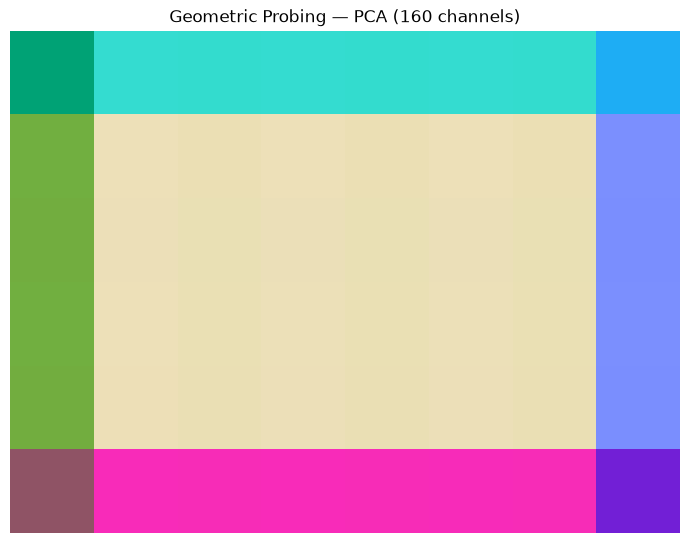

[INFO] Geometric probing completed
[OK] PCA visualization completed


In [33]:
print("=== ENCODER PCA (UNTRAINED MODEL) ===")
if not NYU_AVAILABLE or nyu_ft_batch is None:
    print("[SKIP] no batch available")
else:
    rgb, _ = nyu_ft_batch
    one_img = rgb[:1].to(DEVICE)

    raw_model = METERModel(arch_type=ARCH_TYPE).to(DEVICE)
    raw_model.eval()

    geometric_probing_pca(
        model        = raw_model,
        device       = DEVICE,
        image_tensor = one_img,
        save_path    = None,
    )
    print("[OK] PCA visualization completed")


# 6. Train
This section tests custom loss functions, gradient flow, pre-training steps, and overfitting convergence.

## Test 8 — Balanced loss & gradient flow

In [30]:
print("=== BALANCED LOSS + GRADIENT CHECK ===")
# Build loss with explicit dataset_name (the new API takes it as a constructor arg)
criterion = balanced_loss_function(DEVICE, dataset_name="nyu").to(DEVICE)
print(f"Lambda_1 = {criterion.lambda_1}")
print(f"Lambda_2 = {criterion.lambda_2}")
print(f"Lambda_3 = {criterion.lambda_3}")

# Synthetic pred & GT on the cm scale (range ~50-500 cm)
# IMPORTANT: build pred as a LEAF tensor — otherwise .grad stays None
B = 2
pred = (torch.rand(B, 1, NYU_SIZE[0], NYU_SIZE[1], device=DEVICE) * 400 + 50)
pred = pred.detach().requires_grad_(True)   # make it a leaf with grad
target = torch.rand(B, 1, NYU_SIZE[0], NYU_SIZE[1], device=DEVICE) * 400 + 50

assert pred.is_leaf, "pred must be a leaf tensor for .grad to populate"

l_depth, l_ssim, l_norm, l_grad = criterion(pred, target)
total = l_depth + l_ssim + l_norm + l_grad

print("\n[Loss components]")
print(f"  L1 depth        : {l_depth.item():.4f}")
print(f"  SSIM   (lam*100): {l_ssim.item():.4f}")
print(f"  Normal (lam*100): {l_norm.item():.4f}")
print(f"  Sobel grad      : {l_grad.item():.4f}")
print(f"  TOTAL           : {total.item():.4f}")

assert torch.isfinite(total), "Loss has NaN/Inf"
total.backward()
assert pred.grad is not None,            "pred.grad is None — pred is not a leaf"
assert torch.isfinite(pred.grad).all(),  "pred.grad has NaN/Inf"
print(f"\nGrad norm on pred: {pred.grad.norm().item():.4f}")
print("[OK] Loss returns finite values and gradients flow")

=== BALANCED LOSS + GRADIENT CHECK ===
Lambda_1 = 0.5
Lambda_2 = 100
Lambda_3 = 100

[Loss components]
  L1 depth        : 133.1904
  SSIM   (lam*100): 96.4519
  Normal (lam*100): 98.3874
  Sobel grad      : 1808.2701
  TOTAL           : 2136.2998

Grad norm on pred: 0.0573
[OK] Loss returns finite values and gradients flow


## Test 10 — Depth output range

Uses the full `METERFinetune.forward` (interpolate + softplus): outputs must be **non-negative**.

In [32]:
print("=== DEPTH OUTPUT RANGE (METERFinetune.forward) ===")
if not NYU_AVAILABLE or nyu_ft_batch is None:
    print("[SKIP] NYU batch unavailable")
else:
    ft_model = METERFinetune(arch_type=ARCH_TYPE, dataset_name="nyu").to(DEVICE)
    ft_model.eval()

    rgb, depth_gt = nyu_ft_batch
    rgb = rgb.to(DEVICE); depth_gt = depth_gt.to(DEVICE)

    with torch.no_grad():
        pred = ft_model(rgb)

    print(f"\n[GT — NYU, cm]")
    print(f"  min/max/mean = {depth_gt.min().item():.2f} / {depth_gt.max().item():.2f} / {depth_gt.mean().item():.2f}")
    print(f"  shape        = {tuple(depth_gt.shape)}")

    print(f"\n[PRED — raw network output]")
    print(f"  min/max/mean = {pred.min().item():.4f} / {pred.max().item():.4f} / {pred.mean().item():.4f}")
    print(f"  shape        = {tuple(pred.shape)}")

    assert torch.isfinite(pred).all(), "Pred has NaN/Inf"
    assert (pred >= 0).all(), "Softplus output must be non-negative"
    print("\n[OK] All predictions finite and non-negative")

    if pred.mean().item() < 5.0:
        print("[HINT] Pred mean << GT mean — decoder has not learned scale yet.")
        print("        Expected on randomly-init model. Will rise during training.")


=== DEPTH OUTPUT RANGE (METERFinetune.forward) ===

[INFO] Initializing METERFinetune — dataset: nyu

[INFO] Building METER-xxs
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
[INFO] METERFinetune ready

[GT — NYU, cm]
  min/max/mean = 0.00 / 610.60 / 349.01
  shape        = (4, 1, 192, 256)

[PRED — raw network output]
  min/max/mean = 495.7740 / 500.4288 / 498.0774
  shape        = (4, 1, 192, 256)

[OK] All predictions finite and non-negative


## Test 13 — Single SSL forward + backward step

Loads the SSL checkpoint (if available) and verifies one optimization step works end-to-end.

In [35]:
print("=== SSL SINGLE OPTIMIZATION STEP ===")
if not SSL_CKPT_AVAILABLE:
    print("[SKIP] no SSL checkpoint")
elif not NYU_AVAILABLE:
    print("[SKIP] no NYU dataset for the SSL batch")
else:
    ssl_probe_ds = NYUDataset(
        path   = DATASET_NYU_PATH,
        mode   = "pretrain",
        split  = "train",
        kaggle = False,
    )
    ssl_probe_loader = build_dataloader(
        ssl_probe_ds,
        batch_size=min(4, SSL_BATCH_SIZE),
        shuffle=True,
        drop_last=True,
    )

    ssl_model = LeJEPAMeter.load_from_checkpoint(
        ssl_ckpt_path,
        arch_type = ARCH_TYPE,
        proj_dim  = 64,
        lamb      = 0.02,
        lr        = 5e-4,
    ).to(DEVICE)
    ssl_model.train()

    rgb_batch = next(iter(ssl_probe_loader)).to(DEVICE)
    print(f"Batch shape : {tuple(rgb_batch.shape)}")

    optimizer = torch.optim.AdamW(ssl_model.parameters(), lr=1e-4)
    optimizer.zero_grad()
    loss = ssl_model.training_step(rgb_batch, batch_idx=0)
    loss.backward()
    optimizer.step()

    print(f"\nLoss        : {loss.item():.4f}")
    print(f"\n[OK] SSL backward + optimizer step OK")


=== SSL SINGLE OPTIMIZATION STEP ===

[INFO] NYUDataset — mode=pretrain, split=train, kaggle=False
[INFO] NYUDataset — 96476 samples  (format=rgb_only)
[INFO] DataLoader — batch=4  workers=4  shuffle=True  pin_memory=True

[INFO] Initializing LeJEPA SSL model

[INFO] Building METER-xxs
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
[INFO] Encoder dim: 160
[INFO] LeJEPA model ready
Batch shape : (4, 3, 192, 256)

Loss        : 0.3602

[OK] SSL backward + optimizer step OK


c:\Users\andre\Desktop\CV-project-25-26\.venv\Lib\site-packages\lightning\pytorch\core\module.py:451: You are trying to `self.log()` but the `self.trainer` reference is not registered on the model yet. This is most likely because the model hasn't been passed to the `Trainer`


## Test 14 — Overfit a single batch (THE key sanity test)

If the model **can't** drive the loss down on a single batch in ~200 steps, there is something fundamentally wrong with the architecture / loss / scale. This is the most informative test in the whole notebook.

=== OVERFIT A SINGLE BATCH — METERFinetune ===

[INFO] Initializing METERFinetune — dataset: nyu

[INFO] Building METER-xxs
[INFO] Total params: 713,464
[INFO] Trainable params: 713,464
[INFO] METERFinetune ready
Running 200 steps on 4 images...
  step 000 | total=474.994 | l1=164.834 | pred range=[354.73, 587.69]
  step 020 | total=268.588 | l1=53.471 | pred range=[119.37, 514.51]
  step 040 | total=189.437 | l1=31.038 | pred range=[89.26, 505.80]
  step 060 | total=164.178 | l1=27.333 | pred range=[32.09, 509.10]
  step 080 | total=150.401 | l1=25.048 | pred range=[5.50, 513.26]
  step 100 | total=140.724 | l1=23.752 | pred range=[0.55, 511.91]
  step 120 | total=132.735 | l1=22.488 | pred range=[0.07, 508.80]
  step 140 | total=127.205 | l1=21.461 | pred range=[0.01, 505.08]
  step 160 | total=123.844 | l1=20.541 | pred range=[0.00, 502.55]
  step 180 | total=122.884 | l1=21.089 | pred range=[0.00, 504.17]
  step 199 | total=121.805 | l1=21.462 | pred range=[0.00, 504.82]


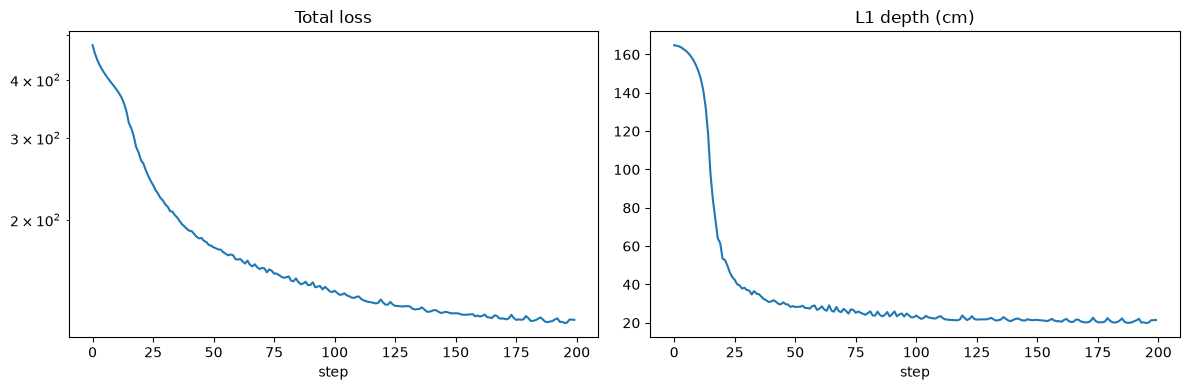


Loss drop: 74.4%  (start 474.99 -> end 121.81)
[OK] Model can overfit a single batch (loss dropped > 50%)


In [36]:
import matplotlib.pyplot as plt

print("=== OVERFIT A SINGLE BATCH — METERFinetune ===")

if not NYU_AVAILABLE or nyu_ft_batch is None:
    print("[SKIP] no batch")
else:
    ft_model = METERFinetune(arch_type=ARCH_TYPE, dataset_name="nyu").to(DEVICE)
    ft_model.train()

    rgb, depth = nyu_ft_batch
    rgb = rgb.to(DEVICE); depth = depth.to(DEVICE)

    optimizer = torch.optim.AdamW(ft_model.parameters(), lr=1e-3)
    loss_fn   = ft_model.loss_fn.to(DEVICE)

    NUM_STEPS = 200
    losses, l1_hist = [], []

    print(f"Running {NUM_STEPS} steps on {rgb.shape[0]} images...")
    for step in range(NUM_STEPS):
        optimizer.zero_grad()
        pred = ft_model(rgb)
        l_depth, l_ssim, l_norm, l_grad = loss_fn(pred, depth)
        total = l_depth + l_ssim + l_norm + l_grad
        total.backward()
        optimizer.step()
        losses.append(total.item())
        l1_hist.append(l_depth.item())
        if step % 20 == 0 or step == NUM_STEPS - 1:
            print(f"  step {step:03d} | total={total.item():.3f} | "
                  f"l1={l_depth.item():.3f} | "
                  f"pred range=[{pred.min().item():.2f}, {pred.max().item():.2f}]")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(losses); axes[0].set_title("Total loss"); axes[0].set_xlabel("step")
    axes[0].set_yscale("log")
    axes[1].plot(l1_hist); axes[1].set_title("L1 depth (cm)"); axes[1].set_xlabel("step")
    plt.tight_layout(); plt.show()

    drop_ratio = (losses[0] - losses[-1]) / max(losses[0], 1e-6)
    print(f"\nLoss drop: {drop_ratio*100:.1f}%  (start {losses[0]:.2f} -> end {losses[-1]:.2f})")
    if drop_ratio > 0.5:
        print("[OK] Model can overfit a single batch (loss dropped > 50%)")
    else:
        print("[WARN] Loss did not drop enough — check scale / activation / grad flow")


# 7. Evaluation
This section tests loading pre-trained weights and checks checkpoint loading integrity.

## Test 12 — SSL checkpoint integrity

In [34]:
print("=== SSL CHECKPOINT INTEGRITY ===")
ssl_ckpt_path = Path(SSL_CKPT_PATH)
if not ssl_ckpt_path.exists():
    alt = Path(MODEL_SAVE_PATH) / "ssl" / "last.ckpt"
    if alt.exists():
        ssl_ckpt_path = alt

if not ssl_ckpt_path.exists():
    print(f"[SKIP] No SSL checkpoint found at {SSL_CKPT_PATH}")
    SSL_CKPT_AVAILABLE = False
else:
    print(f"Checkpoint path : {ssl_ckpt_path}")
    print(f"Size            : {ssl_ckpt_path.stat().st_size / 1e6:.2f} MB")
    ckpt = torch.load(ssl_ckpt_path, map_location="cpu", weights_only=False)
    print(f"\nKeys            : {list(ckpt.keys())[:10]}")
    assert "state_dict" in ckpt, "Missing 'state_dict' in checkpoint!"
    enc_keys = [k for k in ckpt["state_dict"] if k.startswith("encoder.")]
    print(f"Encoder keys    : {len(enc_keys)}")
    if "hyper_parameters" in ckpt:
        print(f"Hyper-params    : {ckpt['hyper_parameters']}")
    print("\n[OK] SSL checkpoint structure valid")
    SSL_CKPT_AVAILABLE = True


=== SSL CHECKPOINT INTEGRITY ===
Checkpoint path : C:\Users\andre\Desktop\CV-project-25-26\models\checkpoints\ssl\last.ckpt
Size            : 10.39 MB

Keys            : ['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'hparams_name', 'hyper_parameters']
Encoder keys    : 250
Hyper-params    : {'arch_type': 'xxs', 'proj_dim': 64, 'num_slices': 256, 'lamb': 0.02, 'lr': 0.0005, 'weight_decay': 0.05, 'warmup_epochs': 10}

[OK] SSL checkpoint structure valid


## Summary

If all the above tests pass:
1. ✅ Environment + datasets correctly loaded
2. ✅ Resolutions aligned with the paper (NYU 192×256, KITTI 192×636)
3. ✅ Model + loss + gradients work end-to-end
4. ✅ The model can overfit a single batch — proof that the code can learn at all
5. ✅ SSL checkpoint loads cleanly and a single step runs

You are safe to launch the long fine-tuning run from `main.ipynb`.